In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

UPLOAD DATASET

In [96]:
df = pd.read_csv('Carbon Emission.csv')

In [97]:
df.head()

,Body Type,Sex,Diet,How Often Shower,Heating Energy Source,Transport,Vehicle Type,Social Activity,Monthly Grocery Bill,Frequency of Traveling by Air,Vehicle Monthly Distance Km,Waste Bag Size,Waste Bag Weekly Count,How Long TV PC Daily Hour,How Many New Clothes Monthly,How Long Internet Daily Hour,Energy efficiency,Recycling,Cooking_With,CarbonEmission
0,overweight,female,pescatarian,daily,coal,public,NaN,often,230,frequently,210,large,4,7,26,1,No,['Metal'],"['Stove', 'Oven']",2238
1,obese,female,vegetarian,less frequently,natural gas,walk/bicycle,NaN,often,114,rarely,9,extra large,3,9,38,5,No,['Metal'],"['Stove', 'Microwave']",1892
2,overweight,male,omnivore,more frequently,wood,private,petrol,never,138,never,2472,small,1,14,47,6,Sometimes,['Metal'],"['Oven', 'Microwave']",2595
3,overweight,male,omnivore,twice a day,wood,walk/bicycle,NaN,sometimes,157,rarely,74,medium,3,20,5,7,Sometimes,"['Paper', 'Plastic', 'Glass', 'Metal']","['Microwave', 'Grill', 'Airfryer']",1074
4,obese,female,vegetarian,daily,coal,private,diesel,often,266,very frequently,8457,large,1,3,5,6,Yes,['Paper'],['Oven'],4743


In [98]:
print(f"Jumlah Baris: {df.shape[0]}")
print(f"Jumlah Kolom: {df.shape[1]}")
print("\n--- Tipe Data dan Informasi Non-Null ---")
df.info()

Jumlah Baris: 10000
Jumlah Kolom: 20

--- Tipe Data dan Informasi Non-Null ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   Body Type                      10000 non-null  str  
 1   Sex                            10000 non-null  str  
 2   Diet                           10000 non-null  str  
 3   How Often Shower               10000 non-null  str  
 4   Heating Energy Source          10000 non-null  str  
 5   Transport                      10000 non-null  str  
 6   Vehicle Type                   3279 non-null   str  
 7   Social Activity                10000 non-null  str  
 8   Monthly Grocery Bill           10000 non-null  int64
 9   Frequency of Traveling by Air  10000 non-null  str  
 10  Vehicle Monthly Distance Km    10000 non-null  int64
 11  Waste Bag Size                 10000 non-null  str  
 12  Waste B

CLEANING DAN PREPROCESSING

In [99]:
# pengecekkan data null dan duplikat
null_counts = df.isnull().sum()[lambda s: s > 0]
print("tidak ada data null" if null_counts.empty else  f" Null: {null_counts}")

dup_count = df.duplicated().sum()
print("tidak ada data duplikat" if dup_count == 0 else f"Duplikat: {dup_count}")


 Null: Vehicle Type    6721
dtype: int64
tidak ada data duplikat


In [100]:
# mengisi nilai null dengan 'Unknown'
df['Vehicle Type'] = df['Vehicle Type'].fillna('Unknown')

In [101]:
# memastikan semua isi kolom CarbonEmission bertipe numerik
df['CarbonEmission'] = pd.to_numeric(df['CarbonEmission'], errors='coerce')

In [102]:
# pembersihan ulang nilai null
df = df.dropna()

In [103]:
# pengecekkan ulang data null daan duplikat
null_counts = df.isnull().sum()[lambda s: s > 0]
print("tidak ada data null" if null_counts.empty else  f" Null: {null_counts}")

dup_count = df.duplicated().sum()
print("tidak ada data duplikat" if dup_count == 0 else f"Duplikat: {dup_count}")

tidak ada data null
tidak ada data duplikat


median CarbonEmission: 2080.0
Status_Emisi
0    5004
1    4996
Name: count, dtype: int64


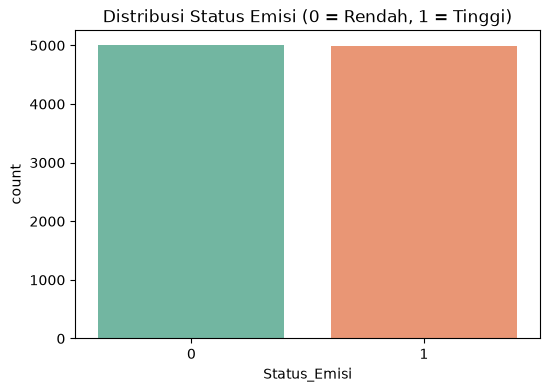

In [104]:
# Menentukan batas median emisi sebagai pemisah kelas (0 = Rendah, 1 = Tinggi)
median_emisi = df['CarbonEmission'].median()

print(f'median CarbonEmission: {median_emisi}')

df['Status_Emisi'] = (df['CarbonEmission'] > median_emisi).astype(int)
print(df['Status_Emisi'].value_counts())

# Visualisasi distribusi target
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Status_Emisi', hue='Status_Emisi', data=df, palette='Set2', legend=False)

plt.title('Distribusi Status Emisi (0 = Rendah, 1 = Tinggi)')
plt.show()

EXPLORATORY DATA ANALYSIS

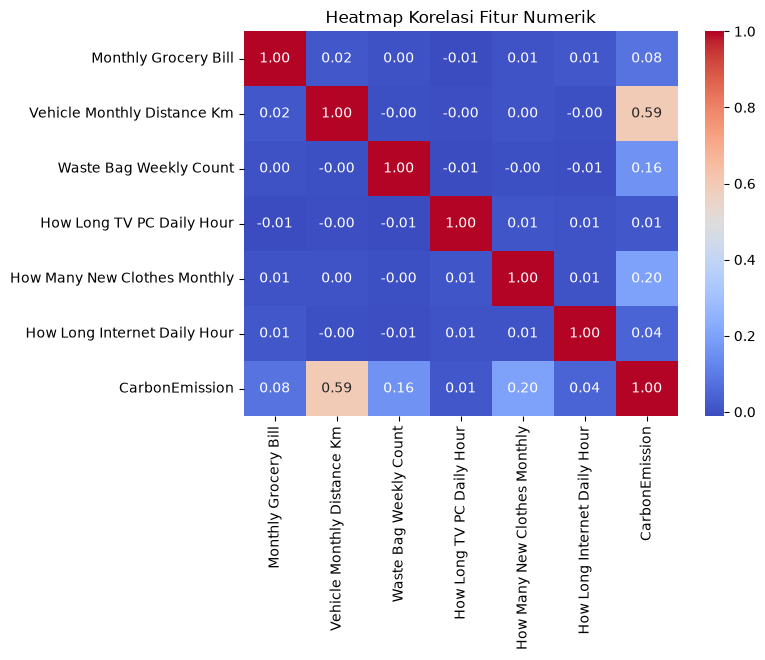

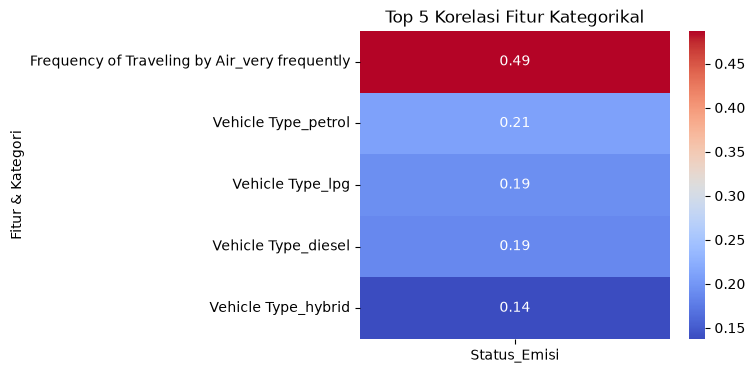

In [105]:
# menampilan gambar korelasi antara masing massing kolom dengan target

# kolom numerikal
kolom_num = ['Monthly Grocery Bill', 'Vehicle Monthly Distance Km', 'Waste Bag Weekly Count', 'How Long TV PC Daily Hour', 'How Many New Clothes Monthly', 'How Long Internet Daily Hour', 'CarbonEmission']

plt.figure(figsize=(7, 5))
sns.heatmap(df[kolom_num].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap Korelasi Fitur Numerik')
plt.show()

# kolom kategorikal
kolom_cat = ['Body Type', 'Sex', 'Diet', 'How Often Shower', 'Heating Energy Source', 'Transport', 'Vehicle Type', 'Social Activity', 'Frequency of Traveling by Air', 'Waste Bag Size', 'Energy efficiency', 'Recycling', 'Cooking_With']

# 1. Ubah kolom kategorikal menjadi angka biner (One-Hot Encoding)
df_encoded = pd.get_dummies(df[kolom_cat], drop_first=True, dtype=int)

# 2. Masukkan kolom target Status_Emisi ke dalam dataframe sementara
df_encoded['Status_Emisi'] = df['Status_Emisi']

# 3. Ambil korelasi terhadap 'Status_Emisi', buang baris 'Status_Emisi' itu sendiri, 
#    lalu ambil 5 teratas dengan nilai korelasi tertinggi untuk menyederhanakan gambar
kor_top5 = df_encoded.corr()[['Status_Emisi']].drop('Status_Emisi').sort_values(by='Status_Emisi', ascending=False).head(5)

# 4. Tampilkan
plt.figure(figsize=(5, 4))
sns.heatmap(kor_top5, annot=True, cmap='coolwarm', fmt='.2f', cbar=True)
plt.title('Top 5 Korelasi Fitur Kategorikal', fontsize=12)
plt.ylabel('Fitur & Kategori')
plt.show()

FEATURE SELECTION

In [106]:
# memilih fitur berdasarkan hasil analisis korelasi
fitur = ['Transport', 'Vehicle Monthly Distance Km', 'How Many New Clothes Monthly',
         'Frequency of Traveling by Air', 'Vehicle Type', 'Waste Bag Weekly Count']

X = pd.get_dummies(df[fitur], drop_first=True, dtype=int)
Y = df['Status_Emisi']

TRAIN - TEST SPLIT

In [107]:
# Membagi data training (80%) dan testing (20%) secara proporsional (stratify)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=1, stratify=Y)

PEMODELAN

In [108]:
# Melatih model Decision Tree dan Random Forest
model_dt = DecisionTreeClassifier(max_depth=3, random_state=1)
model_dt.fit(X_train, Y_train)

model_rf = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=1)
model_rf.fit(X_train, Y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: 

EVALUASI MODEL

In [109]:
# Menghitung akurasi uji dan validasi silang (Cross-Validation)
for nama, model in [('Decision Tree', model_dt), ('Random Forest', model_rf)]:
    akurasi = accuracy_score(Y_test, model.predict(X_test))
    cv = cross_val_score(model, X, Y, cv=5).mean()
    print(f'{nama:15s} | Akurasi uji: {akurasi*100:.2f}% | Rata-rata CV 5-fold: {cv*100:.2f}%')

# laporan klasifikasi decision tree
prediksi_dt = model_dt.predict(X_test)
print("=== CLASSIFICATION REPORT: DECISION TREE ===")
print(classification_report(Y_test, prediksi_dt, target_names=['Rendah', 'Tinggi']))

# laporan klasifikasi random forest
prediksi_rf = model_rf.predict(X_test)
print("=== CLASSIFICATION REPORT: RANDOM FOREST ===")
print(classification_report(Y_test, prediksi_rf, target_names=['Rendah', 'Tinggi']))

Decision Tree   | Akurasi uji: 82.70% | Rata-rata CV 5-fold: 83.27%
Random Forest   | Akurasi uji: 85.70% | Rata-rata CV 5-fold: 86.24%
=== CLASSIFICATION REPORT: DECISION TREE ===
              precision    recall  f1-score   support

      Rendah       0.77      0.93      0.84      1001
      Tinggi       0.91      0.73      0.81       999

    accuracy                           0.83      2000
   macro avg       0.84      0.83      0.83      2000
weighted avg       0.84      0.83      0.83      2000

=== CLASSIFICATION REPORT: RANDOM FOREST ===
              precision    recall  f1-score   support

      Rendah       0.83      0.89      0.86      1001
      Tinggi       0.88      0.82      0.85       999

    accuracy                           0.86      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.86      0.86      0.86      2000



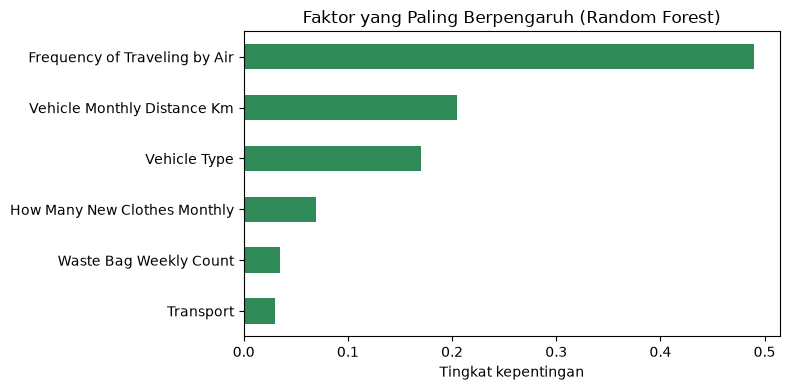

Frequency of Traveling by Air    49.0
Vehicle Monthly Distance Km      20.5
Vehicle Type                     17.0
How Many New Clothes Monthly      7.0
Waste Bag Weekly Count            3.5
Transport                         3.0
dtype: float64


In [110]:
# menampilkan grafik faktor paling berpengaruh
imp = pd.Series(model_rf.feature_importances_, index=X.columns)
imp_asli = imp.groupby(lambda kol: next(f for f in fitur if kol.startswith(f))).sum().sort_values()

plt.figure(figsize=(8, 4))
imp_asli.plot(kind='barh', color='seagreen')
plt.title('Faktor yang Paling Berpengaruh (Random Forest)')
plt.xlabel('Tingkat kepentingan')
plt.tight_layout()
plt.show()

print((imp_asli.sort_values(ascending=False) * 100).round(1))

PREDIKSI DAN INTERPRETASI

In [111]:
# 1. Kamus Pilihan & Label (Menerjemahkan kode data ke Bahasa Indonesia)
opsi_terbang = ['never', 'rarely', 'frequently', 'very frequently']
opsi_kendaraan = ['petrol', 'diesel', 'lpg', 'hybrid', 'electric']
opsi_transport = ['private', 'public', 'walk/bicycle']

label_transport = {
    'private': 'Kendaraan pribadi',
    'public': 'Transportasi umum',
    'walk/bicycle': 'Jalan kaki / sepeda'
}

label_kendaraan = {
    'petrol': 'Bensin',
    'diesel': 'Solar',
    'lpg': 'LPG',
    'hybrid': 'Hybrid',
    'electric': 'Listrik'
}

label_terbang = {
    'never': 'Tidak pernah',
    'rarely': 'Jarang',
    'frequently': 'Sering',
    'very frequently': 'Sangat sering'
}

# 2. Menghitung nilai acuan median dari data historis untuk panduan saran
jarak_umum = int(
    df.loc[df['Transport'] == 'public', 'Vehicle Monthly Distance Km'].median()
)
median_baju = df['How Many New Clothes Monthly'].median()
median_sampah = df['Waste Bag Weekly Count'].median()


def tanya_angka(teks, minimum=0):
    """Fungsi validasi agar input angka dari pengguna selalu valid dan tidak negatif."""
    while True:
        try:
            nilai = float(input(teks))
            if nilai < minimum:
                print(f'Nilai minimal {minimum}, coba lagi.')
                continue
            return nilai
        except ValueError:
            print('Masukkan angka yang valid.')


def tanya_pilihan(teks, opsi, label=None):
    """Fungsi membuat menu pilihan interaktif berbasis nomor."""
    label = label or {}
    print(teks.strip(), flush=True)
    for i, o in enumerate(opsi):
        print(f'  [{i}] {label.get(o, o)}', flush=True)

    while True:
        try:
            idx = int(input('Pilih nomor: '))
            if 0 <= idx < len(opsi):
                return opsi[idx]
            print('Nomor di luar pilihan, coba lagi.', flush=True)
        except ValueError:
            print('Masukkan nomor yang valid.', flush=True)


def probabilitas_tinggi(data):
    """
    Fungsi untuk memproses input pengguna agar memiliki struktur kolom 
    yang persis sama dengan model Random Forest (menggunakan get_dummies & reindex).
    """
    baris = pd.get_dummies(pd.DataFrame([data]), dtype=int)
    baris = baris.reindex(columns=X.columns, fill_value=0)
    return model_rf.predict_proba(baris)[0][1]


def buat_rekomendasi(data):
    """Sistem pakar sederhana (rule-based) untuk menghasilkan saran gaya hidup."""
    saran = []

    if data['Frequency of Traveling by Air'] in ['frequently', 'very frequently']:
        saran.append('Kurangi perjalanan udara: pilih pertemuan daring atau gabungkan urusan.')

    if data['Vehicle Type'] in ['petrol', 'diesel', 'lpg']:
        saran.append('Pertimbangkan kendaraan hybrid/listrik atau berbagi tumpangan.')

    if data['Vehicle Type'] != 'Unknown' and data['Vehicle Monthly Distance Km'] > jarak_umum:
        saran.append('Jarak tempuh kendaraan pribadi cukup jauh: coba alihkan sebagian ke transportasi umum.')

    if data['How Many New Clothes Monthly'] > median_baju:
        saran.append('Kurangi pembelian pakaian baru: coba barang bekas atau tukar pakaian.')

    if data['Waste Bag Weekly Count'] > median_sampah:
        saran.append('Kurangi sampah rumah tangga dengan memilah dan mendaur ulang.')

    return saran or ['Kebiasaanmu sudah ramah lingkungan, pertahankan!']


def status_dari(skor):
    """Menentukan status akhir: TINGGI jika peluang > 50%, sisanya RENDAH."""
    return 'TINGGI' if skor > 0.5 else 'RENDAH'


def jalankan_prediksi():
    """Fungsi utama yang merangkai proses tanya-jawab interaktif hingga hasil keluar."""
    print('=' * 60)
    print(' PREDIKSI STATUS JEJAK KARBON INDIVIDU')
    print('=' * 60)

    # Meminta input utama
    transport = tanya_pilihan('Transportasi utama kamu:', opsi_transport, label_transport)
    
    if transport == 'private':
        jenis = tanya_pilihan('Jenis kendaraan pribadi:', opsi_kendaraan, label_kendaraan)
    else:
        jenis = 'Unknown'

    # Mengumpulkan seluruh data kebiasaan pengguna
    data = {
        'Transport': transport,
        'Vehicle Monthly Distance Km': tanya_angka('Jarak tempuh per bulan (km): '),
        'How Many New Clothes Monthly': tanya_angka('Jumlah pakaian baru per bulan: '),
        'Frequency of Traveling by Air': tanya_pilihan('Seberapa sering naik pesawat:', opsi_terbang, label_terbang),
        'Vehicle Type': jenis,
        'Waste Bag Weekly Count': tanya_angka('Jumlah kantong sampah per minggu: ')
    }

    # Menampilkan ringkasan input
    print('\n' + '=' * 60)
    print(' DATA YANG KAMU MASUKKAN')
    print('=' * 60)
    print(f"Transportasi utama: {label_transport.get(transport, transport)}")
    if jenis != 'Unknown':
        print(f"Jenis kendaraan: {label_kendaraan.get(jenis, jenis)}")
    print(f"Jarak tempuh per bulan: {data['Vehicle Monthly Distance Km']:g} km")
    print(f"Jumlah pakaian baru per bulan: {data['How Many New Clothes Monthly']:g}")
    print(f"Frekuensi naik pesawat: {label_terbang.get(data['Frequency of Traveling by Air'], data['Frequency of Traveling by Air'])}")
    print(f"Jumlah kantong sampah per minggu: {data['Waste Bag Weekly Count']:g}")

    # Melakukan kalkulasi prediksi menggunakan model Machine Learning
    skor = probabilitas_tinggi(data)
    status = status_dari(skor)
    keterangan = 'kurang ramah lingkungan' if status == 'TINGGI' else 'ramah lingkungan'

    print('=' * 60)
    print(f' HASIL: Jejak karbon kamu diprediksi {status} ({keterangan})')
    print(' Catatan: Ini adalah estimasi dari pola data, bukan pengukuran mutlak.')
    print('=' * 60)

    # Menampilkan Evaluasi & Saran Perbaikan
    print('\nEVALUASI KEBIASAAN DAN SARAN')
    print('=' * 60)
    saran = buat_rekomendasi(data)
    pesan_umum = 'Kebiasaanmu sudah ramah lingkungan, pertahankan!'
    saran_perbaikan = [item for item in saran if item != pesan_umum]

    if status == 'RENDAH':
        print('Status emisi kamu tergolong RENDAH.')
        print('Pertahankan kebiasaan baik yang sudah kamu lakukan!')
        if saran_perbaikan:
            print('\nHal yang masih bisa ditingkatkan:')
            for item in saran_perbaikan:
                print(f'- {item}')
    else:
        print('Status emisi kamu tergolong TINGGI.')
        if saran_perbaikan:
            print('\nSaran untuk mengurangi jejak karbon:')
            for item in saran_perbaikan:
                print(f'- {item}')

# Menjalankan program prediksi interaktif
jalankan_prediksi()

 PREDIKSI STATUS JEJAK KARBON INDIVIDU
Transportasi utama kamu:
  [0] Kendaraan pribadi
  [1] Transportasi umum
  [2] Jalan kaki / sepeda
Jenis kendaraan pribadi:
  [0] Bensin
  [1] Solar
  [2] LPG
  [3] Hybrid
  [4] Listrik
Seberapa sering naik pesawat:
  [0] Tidak pernah
  [1] Jarang
  [2] Sering
  [3] Sangat sering

 DATA YANG KAMU MASUKKAN
Transportasi utama: Kendaraan pribadi
Jenis kendaraan: Bensin
Jarak tempuh per bulan: 2000 km
Jumlah pakaian baru per bulan: 4
Frekuensi naik pesawat: Sering
Jumlah kantong sampah per minggu: 5
 HASIL: Jejak karbon kamu diprediksi TINGGI (kurang ramah lingkungan)
 Catatan: Ini adalah estimasi dari pola data, bukan pengukuran mutlak.

EVALUASI KEBIASAAN DAN SARAN
Status emisi kamu tergolong TINGGI.

Saran untuk mengurangi jejak karbon:
- Kurangi perjalanan udara: pilih pertemuan daring atau gabungkan urusan.
- Pertimbangkan kendaraan hybrid/listrik atau berbagi tumpangan.
- Jarak tempuh kendaraan pribadi cukup jauh: coba alihkan sebagian ke transp